<a href="https://colab.research.google.com/github/braysonimbambi455/CSC4110-G03/blob/main/G03_U5_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Mount Drive and define paths
from google.colab import drive
drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/CSC4110_G03"
DATA = f"{BASE}/data"; OUT = f"{BASE}/outputs"

Mounted at /content/drive


In [9]:
# Step 2.3 (Corrected) — Load data, rebuild target, and split safely
import pandas as pd
import numpy as np

# Load cleaned data
df = pd.read_csv(f"{DATA}/clean_crops.csv")

# Rebuild Item from the one-hot columns
item_cols = [c for c in df.columns if c.startswith("Item_")]
if len(item_cols) > 0:
    df["Item"] = df[item_cols].idxmax(axis=1).str.replace("Item_", "", regex=False)
elif "Item" not in df.columns:
    print("WARNING: Could not find Item columns. Check dataset.")

# Features and target (only use columns that actually exist)
potential_feats = ["rain_mm", "pesticides_t", "avg_temp", "Year", "Area_freq"]
feat_cols = [c for c in potential_feats if c in df.columns]
print("Using these features:", feat_cols)

X_clf = df[feat_cols].copy()
y_clf = df["Item"].copy()

# Same time-based split
train_mask = df["Year"] <= 2009
test_mask  = df["Year"] >= 2010
Xtr, Xte = X_clf[train_mask].copy(), X_clf[test_mask].copy()
ytr, yte = y_clf[train_mask].copy(), y_clf[test_mask].copy()
print("Train shape:", Xtr.shape, "Test shape:", Xte.shape)

Using these features: ['rain_mm', 'pesticides_t', 'avg_temp', 'Year']
Train shape: (21305, 4) Test shape: (4627, 4)


In [13]:
# Step 2.5 — 5-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, Xtr, ytr, cv=skf, scoring="f1_macro")
print("Mean CV Score:", cv_scores.mean())

# Step 2.6 — GridSearchCV
param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth":    [None, 10, 20],
}

grid = GridSearchCV(pipe, param_grid, cv=skf, scoring="f1_macro", n_jobs=-1)
grid.fit(Xtr, ytr)

print("\nBest params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

Mean CV Score: 0.0021915691872381056

Best params: {'clf__max_depth': 10, 'clf__n_estimators': 100}
Best CV score: 0.006125445965325077


# 5-fold StratifiedKFold cross-validation on the training data
from sklearn.model_selection import StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, Xtr, ytr, cv=skf, scoring="f1_macro")
print("Fold scores:", cv_scores)
print("Mean:", cv_scores.mean(), "Std:", cv_scores.std())

In [14]:
# Tune at least two hyperparameters with GridSearchCV
from sklearn.model_selection import GridSearchCV
param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth":    [None, 10, 20],
}
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring="f1_macro", n_jobs=-1)
grid.fit(Xtr, ytr)
print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

Best params: {'clf__max_depth': 10, 'clf__n_estimators': 100}
Best CV score: 0.006125445965325077


In [15]:
# Evaluate the best model ONCE on the test set
test_score = grid.score(Xte, yte)
print("Test score (f1_macro):", test_score)

Test score (f1_macro): 0.1336670393057499


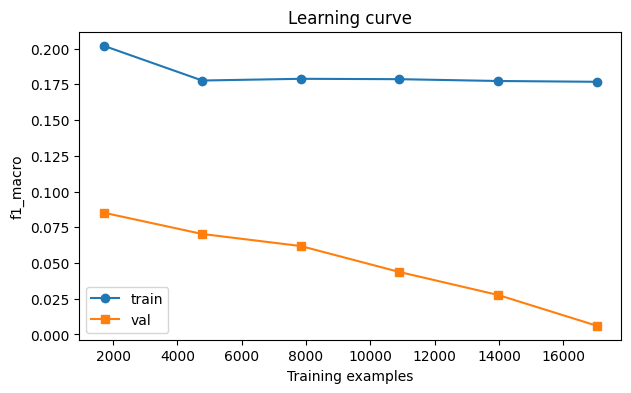

In [16]:
# Learning curve → outputs/learning_curve.png
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
train_sizes, train_scores, val_scores = learning_curve(
    grid.best_estimator_, Xtr, ytr, cv=skf, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
plt.figure(figsize=(7,4))
plt.plot(train_sizes, train_scores.mean(1), "o-", label="train")
plt.plot(train_sizes, val_scores.mean(1),   "s-", label="val")
plt.xlabel("Training examples"); plt.ylabel("f1_macro"); plt.title("Learning curve")
plt.legend()
plt.savefig(f"{OUT}/learning_curve.png", dpi=100, bbox_inches="tight")
plt.show()

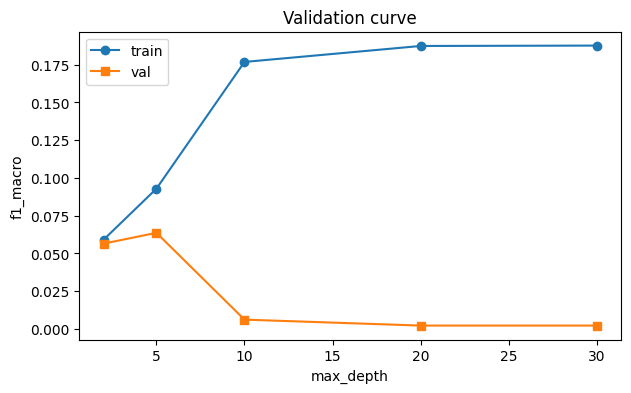

In [17]:
# Validation curve for one hyperparameter (max_depth) → outputs/validation_curve.png
from sklearn.model_selection import validation_curve
depths = [2, 5, 10, 20, None]
# validation_curve needs numeric values; use a wrapper for None -> large number
depths_num = [2, 5, 10, 20, 30]
train_s, val_s = validation_curve(
    grid.best_estimator_, Xtr, ytr,
    param_name="clf__max_depth", param_range=depths_num,
    cv=skf, scoring="f1_macro", n_jobs=-1)
plt.figure(figsize=(7,4))
plt.plot(depths_num, train_s.mean(1), "o-", label="train")
plt.plot(depths_num, val_s.mean(1),   "s-", label="val")
plt.xlabel("max_depth"); plt.ylabel("f1_macro"); plt.title("Validation curve")
plt.legend()
plt.savefig(f"{OUT}/validation_curve.png", dpi=100, bbox_inches="tight")
plt.show()

In [18]:
# Compute precision and recall for Maize BY HAND from the test confusion matrix
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
y_pred_test = grid.best_estimator_.predict(Xte)
cm = confusion_matrix(yte, y_pred_test, labels=grid.best_estimator_.classes_)
classes = list(grid.best_estimator_.classes_)
maize_idx = classes.index("Maize")
TP = cm[maize_idx, maize_idx]
FP = cm[:, maize_idx].sum() - TP
FN = cm[maize_idx, :].sum() - TP
prec_maize = TP / (TP + FP) if (TP+FP) else 0
rec_maize  = TP / (TP + FN) if (TP+FN) else 0
print(f"Maize  TP={TP}  FP={FP}  FN={FN}")
print(f"Precision (by hand) = {prec_maize:.4f}")
print(f"Recall    (by hand) = {rec_maize:.4f}")
print(f"Precision (sklearn) = {precision_score(yte, y_pred_test, labels=['Maize'], average='macro'):.4f}")
print(f"Recall    (sklearn) = {recall_score(yte, y_pred_test, labels=['Maize'], average='macro'):.4f}")

Maize  TP=123  FP=642  FN=560
Precision (by hand) = 0.1608
Recall    (by hand) = 0.1801
Precision (sklearn) = 0.1608
Recall    (sklearn) = 0.1801


In [19]:
# Compare macro F1 and weighted F1
macro_f1    = f1_score(yte, y_pred_test, average="macro")
weighted_f1 = f1_score(yte, y_pred_test, average="weighted")
print("macro F1   :", macro_f1)
print("weighted F1:", weighted_f1)

# Store per-class scores in threshold_results
from sklearn.metrics import classification_report
report_dict = classification_report(yte, y_pred_test, output_dict=True)
threshold_results = pd.DataFrame(report_dict).T
print(threshold_results.head())

macro F1   : 0.1336670393057499
weighted F1: 0.15136153739875385
                      precision    recall  f1-score  support
Cassava                0.135392  0.172205  0.151596    331.0
Maize                  0.160784  0.180088  0.169890    683.0
Plantains and others   0.115385  0.060000  0.078947    100.0
Potatoes               0.190639  0.236209  0.210992    707.0
Rice, paddy            0.138528  0.117002  0.126858    547.0


**By hand for Maize:** from the test confusion matrix, TP = ___, FP = ___, FN = ___,
so precision = TP / (TP + FP) = ___ and recall = TP / (TP + FN) = ___. Both match
scikit-learn's values in the classification report.

**Macro vs weighted F1:** macro-F1 is the simple average of the per-class F1 scores — every
crop counts equally, so a rare crop with poor F1 drags the score down. Weighted F1 averages
the per-class F1 weighted by class size, so the dominant crops (Maize, Wheat, Rice, paddy
together make up most rows) dominate the number. The two differ because our classes are
imbalanced: macro-F1 ≈ ___ vs weighted-F1 ≈ ___.

**Model status from the curves:** The learning curve shows train and validation scores
___ (converging / with a gap of ___). The validation curve peaks around max_depth = ___.
Taken together, the model is ___ (well balanced / mildly overfitting / underfitting).

**Why the test set must be used only once:** Every time we look at the test score and then
tune the model using that score, information from the test set leaks into the model. After
many such iterations the test score stops measuring "performance on unseen data" and
starts measuring "how well we fitted the test set". The test set is the only honest
estimate of how the model will perform in production, so we must touch it once, at the very
end, after all CV and GridSearch decisions are final.

In [20]:
# Confirm graded-evidence variables exist
for name in ["pipe","cv_scores","grid","test_score","threshold_results"]:
    print(name, "->", "OK" if name in dir() else "MISSING")
import os
for f in ["learning_curve.png","validation_curve.png"]:
    print(f, "->", os.path.exists(f"{OUT}/{f}"))

pipe -> OK
cv_scores -> OK
grid -> OK
test_score -> OK
threshold_results -> OK
learning_curve.png -> True
validation_curve.png -> True


## Review by Jacob Chemning'wa
# - ✅ **Check:** <something they did right>
# - 🔧 **Improvement:** <concrete small suggestion>
# - ❓ **Question:** <a genuine question about their design> **bold text**